In [1]:
# Instalação do Kagglehub
!pip install -q kagglehub

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

# 1. Obtenção dos dados automaticamente do Kaggle
path = kagglehub.dataset_download("MujtabaMatin/air-quality-and-pollution-assessment")
print("Caminho dos arquivos:", path)

# Carregando o arquivo CSV principal
import os
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
arquivo_csv = os.path.join(path, csv_files[0])

df = pd.read_csv(arquivo_csv)

# 2. Exploração Inicial (EDA Básica)
print("\n--- Informações do Dataset ---")
print(df.info())

print("\n--- Estatísticas Básicas ---")
print(df.describe())

print("\n--- Verificação de Dados Ausentes ---")
print(df.isna().sum())

Using Colab cache for faster access to the 'air-quality-and-pollution-assessment' dataset.
Caminho dos arquivos: /kaggle/input/air-quality-and-pollution-assessment

--- Informações do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Temperature                    5000 non-null   float64
 1   Humidity                       5000 non-null   float64
 2   PM2.5                          5000 non-null   float64
 3   PM10                           5000 non-null   float64
 4   NO2                            5000 non-null   float64
 5   SO2                            5000 non-null   float64
 6   CO                             5000 non-null   float64
 7   Proximity_to_Industrial_Areas  5000 non-null   float64
 8   Population_Density             5000 non-null   int64  
 9   Air Quality                    5

In [2]:
# Cria uma cópia da tabela e preenche os números que estão faltando com o valor do meio (mediana)
colunas_numericas = df.select_dtypes(include=['number']).columns
df_limpo = df.copy()
df_limpo[colunas_numericas] = df_limpo[colunas_numericas].fillna(df_limpo[colunas_numericas].median())

# Define qual é a coluna de resposta que a inteligência artificial vai tentar adivinhar
coluna_alvo = 'Air Quality'

# Separa os dados: 'X' guarda todas as pistas (os poluentes) e 'y' guarda a resposta certa
X = df_limpo.drop(columns=[coluna_alvo])
y = df_limpo[coluna_alvo]

# Pega a ferramenta que divide a tabela em duas partes para o aprendizado
from sklearn.model_selection import train_test_split
# Separa 70% para a IA treinar e 30% para testar depois (o random_state garante que a divisão seja sempre igual)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Mostra na tela o tamanho (linhas e colunas) da parte separada para o treino
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (3500, 9)
y_train shape: (3500,)


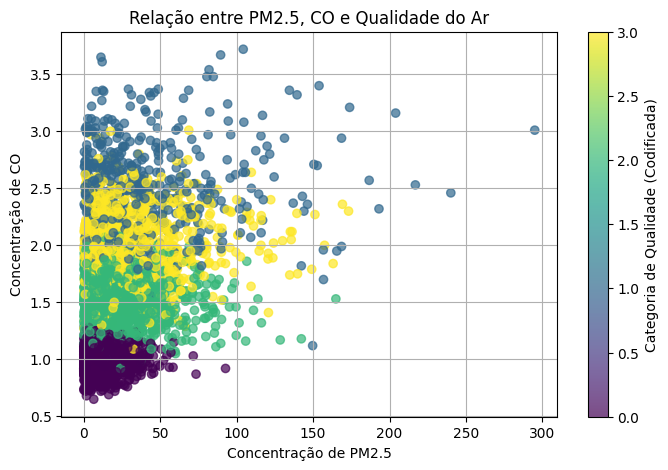

In [3]:
# Cria uma "folha de papel" em branco com o tamanho ideal para o gráfico ficar bonito
plt.figure(figsize=(8, 5))

# Desenha o gráfico de bolinhas (dispersão):
# Eixo X = quantidade de PM2.5, Eixo Y = quantidade de CO
# As cores ('c') mudam de acordo com a categoria da qualidade do ar, deixando a visualização transparente (alpha=0.7)
plt.scatter(df_limpo['PM2.5'], df_limpo['CO'], c=y.astype('category').cat.codes, cmap='viridis', alpha=0.7)

# Coloca um título principal lá em cima no gráfico
plt.title('Relação entre PM2.5, CO e Qualidade do Ar')

# Dá um nome para a linha deitada (eixo horizontal)
plt.xlabel('Concentração de PM2.5')

# Dá um nome para a linha em pé (eixo vertical)
plt.ylabel('Concentração de CO')

# Adiciona aquela barrinha de cores na lateral para servir de legenda das categorias
plt.colorbar(label='Categoria de Qualidade (Codificada)')

# Desenha linhas quadriculadas de fundo para facilitar a leitura dos pontos
plt.grid(True)

# Manda o computador desenhar e mostrar o gráfico na tela
plt.show()

Acurácia Geral do Modelo: 87.80%



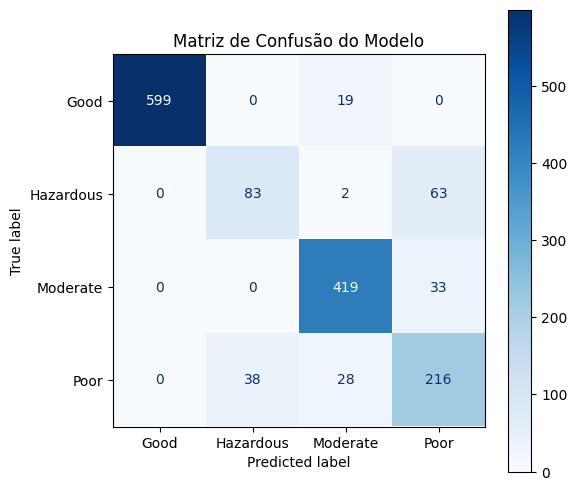

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Cria o modelo de Inteligência Artificial (Árvore de Decisão) limitando a 3 níveis de profundidade
# para que as regras fiquem simples de entender, mantendo o "random_state=42" para o resultado ser sempre igual
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)

# Ensina o modelo usando os dados de treino (as pistas e as respostas certas)
modelo.fit(X_train, y_train)

# Pede para o modelo adivinhar as respostas usando a parte dos dados que ele nunca viu (dados de teste)
y_pred = modelo.predict(X_test)

# Compara as respostas que a IA deu com as respostas certas e calcula a porcentagem de acerto
acuracia = accuracy_score(y_test, y_pred)
# Mostra na tela a porcentagem de acerto geral do modelo formatada com duas casas decimais
print(f"Acurácia Geral do Modelo: {acuracia * 100:.2f}%\n")

# Cria uma figura em formato de quadrado para desenhar a Matriz de Confusão
fig, ax = plt.subplots(figsize=(6, 6))

# Desenha o gráfico que mostra onde a IA acertou e onde errou em cada categoria, usando tons de azul
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap='Blues')

# Coloca um título no gráfico da Matriz de Confusão
plt.title("Matriz de Confusão do Modelo")

# Manda o computador mostrar o gráfico na tela
plt.show()

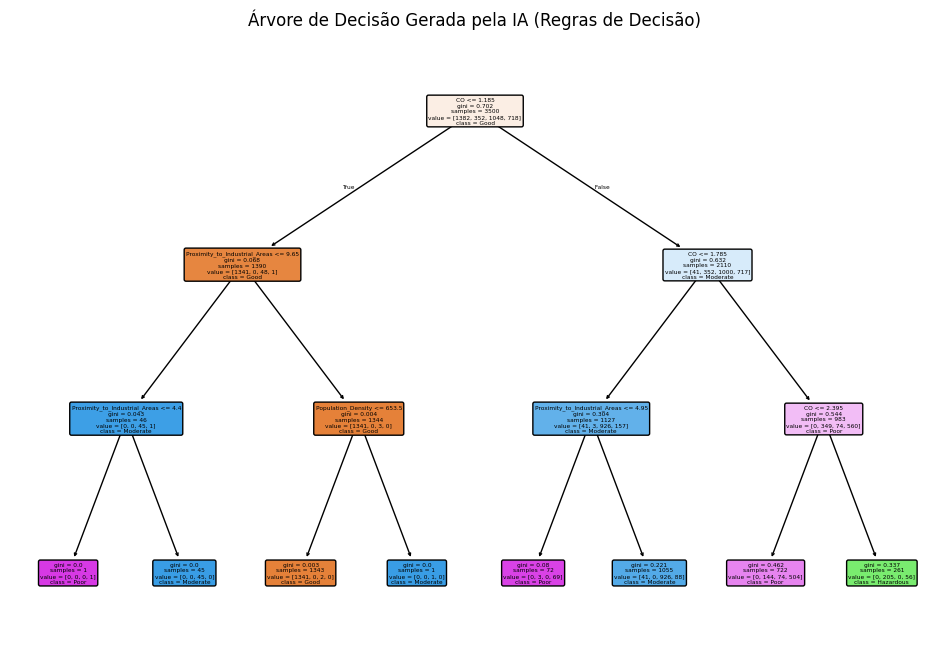

In [5]:
# Pega a ferramenta para desenhar a árvore de decisão em formato de esquema visual
from sklearn.tree import plot_tree

# Cria uma "folha de papel" grande (tamanho 12 por 8) para o desenho da árvore caber direitinho
plt.figure(figsize=(12, 8))

# Desenha a árvore usando o modelo que a IA treinou:
# - feature_names coloca o nome de cada coluna (os poluentes) nas perguntas da árvore
# - class_names converte o nome de cada categoria de qualidade do ar para texto
# - filled=True pinta as caixinhas com cores para ficar fácil de ver qual é a mais forte
# - rounded=True deixa as bordinhas das caixinhas arredondadas
plot_tree(modelo, feature_names=X.columns, class_names=[str(c) for c in modelo.classes_],
          filled=True, rounded=True, proportion=False)

# Coloca um título bem claro no topo do desenho da árvore
plt.title("Árvore de Decisão Gerada pela IA (Regras de Decisão)")

# Manda o computador exibir o desenho da árvore na tela
plt.show()